# TD 6 : regrouper sans étiquettes (clustering)

**BUT INFO3 Développeur IA, R5.C.08, IA5, Partie 1**
M. Sakkari, IUT de La Rochelle

> **À rendre :** les cellules « À vous » complétées, dans votre dépôt GitLab.

## Dans ce TD, on apprend à...
- **regrouper** des données (X) sans connaître la bonne réponse (Y), avec l'algorithme **K-means** ;
- **choisir le nombre de groupes**, avec deux courbes (le coude et la silhouette) ;
- **regrouper autrement**, avec **DBSCAN** et le **clustering hiérarchique** ;
- **vérifier** si les groupes trouvés ont un sens, avec les images de chiffres (TD 5) et les sons (TD 4).

## Les données
**Digits** (« chiffres ») : les 1 797 images de chiffres écrits à la main du TD 5. Chaque image est un carré de **8 × 8 pixels**, donc une ligne de 64 nombres. Les 60 sons du TD 4 (des chiffres prononcés par george, jackson et lucas) servent dans la Partie 5.

> **Comment travailler :** une cellule « Démo » est déjà écrite, il faut la lancer et la lire. Une cellule « À vous » est à compléter : remplacez les `...` par votre code. **Exécutez les cellules dans l'ordre, de haut en bas.** Si vous redémarrez le noyau (le programme Python qui exécute les cellules), relancez d'abord la première cellule de code, celle qui charge les outils.

## Petit lexique avant de commencer

Ces mots reviennent dans tout le TD. Ils sont aussi expliqués au moment où on s'en sert.

| Mot | Ce que ça veut dire | Exemple |
|---|---|---|
| **Exemple** | une ligne du tableau de données | une image, ou un son |
| **Étiquette** (ou **vrai chiffre**) | la bonne réponse associée à un exemple | l'image n°100 a pour étiquette 4 |
| **Apprentissage supervisé** | on connaît l'étiquette de chaque exemple pendant l'entraînement | TD 5 : le perceptron apprend avec les vrais chiffres |
| **Clustering** (ou **regroupement**) | former des **groupes** d'exemples qui se ressemblent, sans connaître les étiquettes. On dit aussi qu'on fait de l'**apprentissage non supervisé** | TD 6 : on cache les vrais chiffres et on regroupe les images qui se ressemblent |
| **Groupe** (en anglais *cluster*) | un paquet d'exemples proches les uns des autres | le groupe 3 contient 180 images |
| **K** | le nombre de groupes qu'on demande à l'algorithme | K = 10 : on veut 10 groupes |
| **Centre** | le point « moyen » d'un groupe : pour chaque pixel, la moyenne de ses valeurs dans toutes les images du groupe | deux images de 4 pixels, (0, 8, 16, 0) et (0, 12, 0, 4) : le centre vaut (0, 10, 8, 2) |
| **Distance euclidienne** | la distance « en ligne droite » entre deux points (vue en BD5) | 5 cm entre deux points sur une feuille |
| **Tableau croisé** | un tableau qui compte, pour chaque groupe (en ligne) et chaque vrai chiffre (en colonne), le nombre d'images | 25 images du groupe 3 sont de vrais 3 |
| **Pureté** | le pourcentage d'exemples qui ont l'étiquette la plus fréquente de leur groupe | un groupe de 10 images : 6 sont des 3, 3 sont des 7 et 1 est un 2. Le chiffre le plus fréquent est le 3 : pureté = 6 ÷ 10 × 100 = 60 % |
| **Inertie** | la somme, sur toutes les images, de la distance au carré entre l'image et le centre de son groupe. Petite : les groupes sont serrés | deux images à 2 et 3 du centre de leur groupe : 2² + 3² = 13 |
| **Méthode du coude** | permet de choisir le nombre optimal de groupes (*clusters*) en repérant le point de la courbe d'inertie où sa baisse ralentit nettement | on teste plusieurs nombres de groupes K, on trace la courbe d'inertie et on choisit le point qui ressemble à un coude |
| **Silhouette** | mesure à quel point une image est proche des images de son groupe et éloignée des images des autres groupes | une image est bien regroupée avec des images qui lui ressemblent et qui sont différentes de celles des autres groupes : son score de silhouette est proche de 1 |
| **PCA** (*Principal Component Analysis*) | une méthode vue au TD 3 qui résume beaucoup de colonnes en quelques-unes, en gardant l'essentiel de la variation | 64 colonnes de pixels résumées en 10 colonnes |
| **DBSCAN** | un algorithme qui forme des groupes en recherchant des zones où beaucoup d'images sont proches. Il ne nécessite pas de définir le nombre de groupes à l'avance | des images de chiffres qui se ressemblent forment un groupe |
| **eps** | un paramètre de DBSCAN qui définit la distance maximale pour considérer deux images comme voisines | eps = 0,7 : deux images distantes de 0,5 sont voisines, mais pas si leur distance est de 0,9 |
| **min_samples** | un paramètre de DBSCAN qui définit le nombre minimal d'images dans le voisinage, image comprise, pour qu'un point soit considéré comme **dense** | min_samples = 5 : il faut au moins 5 images dans le voisinage |
| **Point dense** | une image qui a suffisamment d'images voisines autour d'elle | si min_samples = 5, une image est considérée comme un point dense si elle a au moins 5 images dans son voisinage, elle comprise |
| **Bruit** | une image que DBSCAN ne peut rattacher à aucun groupe. Elle reçoit le numéro de groupe -1 | une image de chiffre très différente des autres |
| **Clustering hiérarchique** | une méthode qui construit les groupes progressivement, en fusionnant les deux groupes les plus proches | on commence avec 1 797 groupes, puis on les fusionne progressivement jusqu'à n'en avoir plus qu'un |
| **Dendrogramme** | un arbre qui représente les fusions successives des groupes. On le coupe à une certaine hauteur pour obtenir plusieurs groupes | couper l'arbre à une hauteur donnée peut permettre d'obtenir 4 groupes |
| **Lien** (*linkage*) | la méthode utilisée pour calculer la distance entre deux groupes | avec le lien single, on mesure la distance entre les deux images les plus proches des deux groupes |
| **Standardiser** | transformer les valeurs de chaque colonne pour obtenir une moyenne de 0 et un écart-type de 1 | le centroïde (en hertz) et le ZCR (entre 0 et 1) pèsent alors autant |

In [ ]:
# Objectif : charger les outils et les images de chiffres.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

# load_digits charge les 1 797 images et leurs chiffres (aucun fichier à télécharger)
chiffres = load_digits()

images = chiffres.images       # les images sous forme de carrés 8 × 8
X = chiffres.data / 16.0       # les mêmes images, une image par ligne de 64 nombres (valeurs entre 0 et 1)
y = chiffres.target            # le vrai chiffre de chaque image (0 à 9) : on ne s'en servira que pour juger

print("Tableau X :", X.shape, "(une ligne par image, une colonne par pixel)")

# Partie 1 : Regrouper sans connaître les chiffres (K-means)

### Concept

Au TD 5, on connaissait la bonne réponse de chaque image : c'était `y`. On disait qu'on faisait de l'**apprentissage supervisé**.

Ici, on cache `y`. On a 1 797 images, et aucun chiffre. Peut-on quand même **regrouper** les images qui se ressemblent ? C'est le **clustering**. On parle d'**apprentissage non supervisé**.

**K-means** est l'un des algorithmes de regroupement les plus utilisés. On choisit à l'avance le nombre de groupes **K**. Puis :
1. on place K **centres** au hasard ;
2. chaque image rejoint le groupe du **centre le plus proche** (au sens de la distance euclidienne) ;
3. on **recalcule chaque centre** : pour chaque pixel, on fait la moyenne de ses valeurs dans les images du groupe ;
4. on répète les étapes 2 et 3 jusqu'à ce que plus rien ne change.

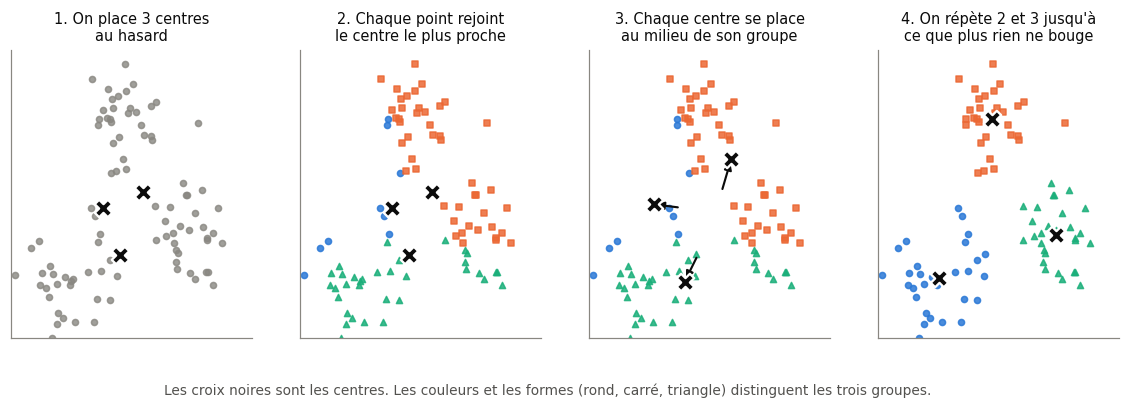

Ce dessin est un exemple simple, avec des points en 2 dimensions. Sur les images de chiffres, c'est le même principe, avec 64 dimensions.


> **Attention :** les numéros de groupes (0, 1, 2...) sont donnés au hasard par l'algorithme. Le groupe 3 n'est pas « le chiffre 3 ».

### Démo : K = 10 groupes

On demande 10 groupes, parce qu'on sait qu'il y a 10 chiffres. On ne donne **pas `y`** à l'algorithme.

In [ ]:
# Objectif : regrouper les 1 797 images en 10 groupes, sans utiliser les vrais chiffres.
from sklearn.cluster import KMeans

# n_clusters=10 : on veut 10 groupes
# n_init=10 : l'algorithme est lancé 10 fois avec des centres de départ différents, on garde le meilleur résultat
# random_state=42 : le même nombre donne toujours les mêmes centres de départ, donc les mêmes résultats
km = KMeans(n_clusters=10, n_init=10, random_state=42)
groupes = km.fit_predict(X)          # on donne seulement X : y n'est pas utilisé

print("Nombre d'images dans chaque groupe :", np.bincount(groupes))

# Une ligne par groupe : le centre (image moyenne) puis 10 images tirées au hasard dans ce groupe
hasard = np.random.default_rng(0)       # graine fixée : on retrouve toujours les mêmes images
fig, axes = plt.subplots(10, 11, figsize=(9.5, 9))
for numero in range(10):
    # Le centre du groupe, dessiné comme une image 8 × 8 (c'est une image "moyenne")
    axes[numero, 0].imshow(km.cluster_centers_[numero].reshape(8, 8), cmap="gray_r")
    axes[numero, 0].set_ylabel(f"groupe {numero}", rotation=0, ha="right", va="center", fontsize=9)
    axes[numero, 0].set_xticks([])
    axes[numero, 0].set_yticks([])
    # np.where donne les numéros des images du groupe ; choice en tire 10 au hasard
    tirage = hasard.choice(np.where(groupes == numero)[0], 10, replace=False)
    for colonne, i in enumerate(tirage):
        axes[numero, colonne + 1].imshow(images[i], cmap="gray_r")
        axes[numero, colonne + 1].axis("off")
axes[0, 0].set_title("centre", fontsize=9)
axes[0, 5].set_title("10 images du groupe, tirées au hasard", fontsize=9)
plt.subplots_adjust(wspace=0.05, hspace=0.08, left=0.14)
plt.show()

**Lecture du résultat.** Chaque ligne est un groupe. La première image est le **centre** du groupe (son image moyenne), les 10 autres sont des images du groupe. Les groupes 1, 5, 9 ne contiennent presque qu'un seul chiffre. Les groupes 2, 3, 8 **mélangent** plusieurs chiffres.

### Comparer les groupes à la réalité

Les groupes sont faits. Sont-ils bons ? Pour le savoir, on utilise les vrais chiffres, que K-means n'a **pas** vus. On s'en sert **après**, seulement pour vérifier.

- Le **tableau croisé** montre, pour chaque groupe, combien d'images de chaque vrai chiffre il contient.
- La **pureté** résume ce tableau en un pourcentage. Plus il est proche de 100 %, plus chaque groupe ne contient qu'un seul chiffre.

In [ ]:
# Objectif : comparer les groupes trouvés aux vrais chiffres.

# crosstab compte, pour chaque groupe (ligne) et chaque vrai chiffre (colonne), le nombre d'images
tableau_croise = pd.crosstab(groupes, y, rownames=["groupe"], colnames=["vrai chiffre"])
print(tableau_croise)

# Pureté : dans chaque groupe, on garde le nombre d'images du chiffre majoritaire (max de la ligne),
# on additionne sur tous les groupes, puis on divise par le nombre total d'images
purete = tableau_croise.max(axis=1).sum() / len(y)
print("\nPureté :", round(purete, 3))

**Lecture du résultat.** La pureté est de **79,4 %**. Sans connaître un seul chiffre, K-means retrouve le bon chiffre pour environ 8 images sur 10. Groupe par groupe :

- groupe 0 : chiffre majoritaire **2**, 148 images sur 176 (84 %)
- groupe 1 : chiffre majoritaire **0**, 177 images sur 179 (99 %)
- groupe 2 : chiffre majoritaire **1**, 55 images sur 89 (62 %)
- groupe 3 : chiffre majoritaire **8**, 102 images sur 226 (45 %)
- groupe 4 : chiffre majoritaire **7**, 170 images sur 198 (86 %)
- groupe 5 : chiffre majoritaire **6**, 177 images sur 182 (97 %)
- groupe 6 : chiffre majoritaire **3**, 155 images sur 181 (86 %)
- groupe 7 : chiffre majoritaire **5**, 137 images sur 157 (87 %)
- groupe 8 : chiffre majoritaire **9**, 139 images sur 241 (58 %)
- groupe 9 : chiffre majoritaire **4**, 166 images sur 168 (99 %)

- Les groupes 1, 5, 9 sont très purs : plus de 90 % d'un seul chiffre.
- Les groupes 2, 3, 8 sont mélangés : K-means y a rangé ensemble des images de chiffres différents.

Le regroupement n'est ni parfait, ni aléatoire. Il suit la ressemblance des dessins, et certains chiffres se ressemblent plus que d'autres.

### À vous : et si on se trompe sur K ?

En pratique, on ne sait pas combien il y a de groupes. Essayons avec **K = 5**, alors qu'il y a 10 chiffres.

**À faire :** relancez K-means avec 5 groupes, puis calculez la pureté.

**Questions :**
1. Que devient la pureté avec K = 5 ?
2. Pourquoi la pureté change-t-elle ?

In [ ]:
# Objectif : voir ce que devient le regroupement avec K = 5 au lieu de 10.

# TODO : refaire les trois étapes de la démo avec n_clusters=5
#        1. créer KMeans(n_clusters=5, n_init=10, random_state=42)
#        2. calculer les groupes avec fit_predict(X)
#        3. calculer le tableau croisé (pd.crosstab) et la pureté
groupes_5 = ...
tableau_5 = ...
purete_5 = ...
print("Pureté avec K = 5 :", purete_5)

# Partie 2 : Choisir K

### Concept

En pratique, on ne connaît pas K. On ne peut pas utiliser la pureté, parce qu'elle demande les vrais chiffres. Il faut des mesures qui n'utilisent **pas** les vrais chiffres. Il y en a deux : **l'inertie** et **la silhouette**. On les calcule seulement avec les images et les groupes, pour plusieurs valeurs de K.

- **L'inertie** mesure si les images sont **serrées** autour du centre de leur groupe. Elle **baisse toujours** quand K augmente, puisque les groupes deviennent plus petits. On cherche le **coude** : le K après lequel la baisse devient beaucoup plus lente.
- **La silhouette** mesure si chaque image est **mieux rangée** dans son groupe que dans le groupe voisin. Elle vaut au plus 1. On cherche le K pour lequel la silhouette moyenne est la **plus grande**.

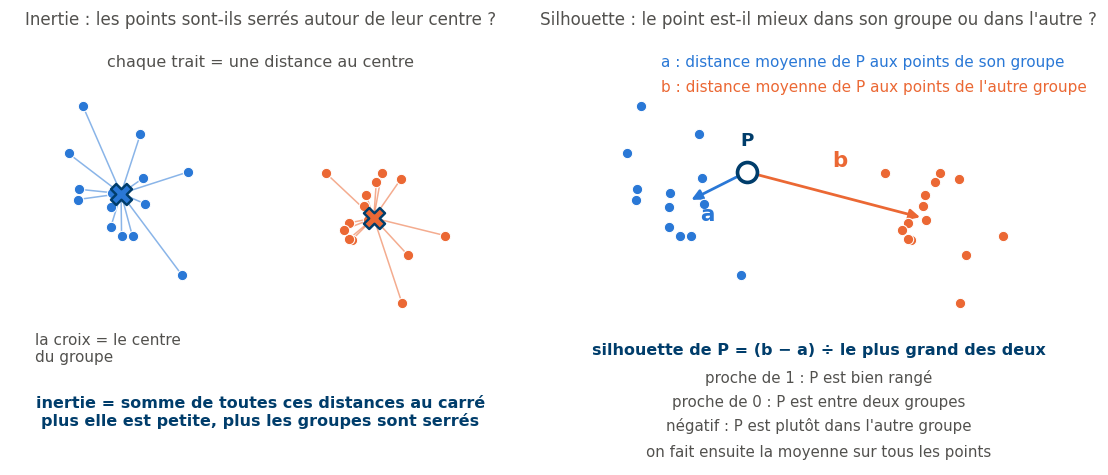

Références : [l'inertie dans K-means](https://scikit-learn.org/stable/modules/clustering.html#k-means) et [le coefficient de silhouette](https://scikit-learn.org/stable/modules/clustering.html#silhouette-coefficient) (guide utilisateur de scikit-learn), [`silhouette_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).

### Démo : les deux courbes pour K de 2 à 15

In [ ]:
# Objectif : calculer l'inertie et la silhouette pour K de 2 à 15, sans utiliser les vrais chiffres.
from sklearn.metrics import silhouette_score

valeurs_k = range(2, 16)
inerties, silhouettes = [], []
for k in valeurs_k:
    km_k = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inerties.append(km_k.inertia_)                                # inertia_ : l'inertie, calculée par scikit-learn
    silhouettes.append(silhouette_score(X, km_k.labels_))        # silhouette moyenne sur toutes les images

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(valeurs_k, inerties, "o-")
axes[0].set_title("Inertie selon K (on cherche un coude)")
axes[0].set_xlabel("K : nombre de groupes")
axes[0].set_ylabel("Inertie")
axes[1].plot(valeurs_k, silhouettes, "o-", color="#eb6834")
axes[1].set_title("Silhouette selon K (on cherche le maximum)")
axes[1].set_xlabel("K : nombre de groupes")
axes[1].set_ylabel("Silhouette moyenne")
plt.tight_layout()
plt.show()

# argmax donne la position de la plus grande valeur de la liste
meilleur_k = valeurs_k[int(np.argmax(silhouettes))]
print("K avec la plus grande silhouette :", meilleur_k)
print("Cette silhouette vaut :", round(max(silhouettes), 3))

**Lecture du résultat.**
- **Inertie :** elle baisse tout le temps. La baisse ralentit un peu après K = 9 : elle passe de 5,0 % entre K = 8 et K = 9 à 3,1 % entre K = 9 et K = 10. Il y a donc un **petit coude** vers K = 9 ou 10, mais il n'est pas très net.
- **Silhouette :** la plus grande valeur est pour K = 9 (0,189). De K = 10 à K = 15, elle reste presque la même (0,182 à 0,187).
- Toutes les silhouettes sont **petites** (moins de 0,2) : les groupes de chiffres ne sont pas très bien séparés.

Les deux courbes montrent donc que K est **autour de 9 ou 10**. Mais elles ne désignent pas un seul K avec certitude.

### À vous : comparer K = 5 et K = 10

**À faire :** calculez la silhouette moyenne du regroupement en 5 groupes, puis du regroupement en 10 groupes, avec `silhouette_score`.

**Questions :**
1. Quelle est la silhouette pour K = 5 ? Et pour K = 10 ?
2. Quelle valeur de K garde-t-on ?

In [ ]:
# Objectif : comparer la silhouette de K = 5 et de K = 10.

# On refait les deux regroupements
groupes_5 = KMeans(n_clusters=5, n_init=10, random_state=42).fit_predict(X)
groupes_10 = KMeans(n_clusters=10, n_init=10, random_state=42).fit_predict(X)

# TODO : la silhouette moyenne de chaque regroupement
#        silhouette_score(X, groupes) prend les images X et les groupes trouvés
silhouette_5 = ...
silhouette_10 = ...
print("Silhouette pour K = 5 :", silhouette_5)
print("Silhouette pour K = 10 :", silhouette_10)

# Partie 3 : Regrouper par zones denses (DBSCAN)

### Concept

K-means demande de choisir K à l'avance, et il range **toutes** les images dans un groupe. **DBSCAN** fonctionne autrement. Il cherche des **zones denses** : des endroits où beaucoup d'images sont proches les unes des autres. Il n'a pas besoin de K. Il laisse de côté les images isolées : c'est le **bruit**.

Il utilise deux réglages :
- **eps** : le rayon d'un cercle tracé autour d'une image ;
- **min_samples** : le nombre minimal d'images dans ce cercle (elle comprise) pour que l'image soit un **point dense**.

Le principe, en quatre étapes :
1. pour chaque image, on compte les images qui sont à moins de eps (distance euclidienne) ;
2. si elles sont au moins min_samples, l'image est un **point dense** ;
3. les points denses proches les uns des autres forment un même groupe ;
4. une image proche d'un point dense rejoint son groupe ; sinon, c'est du **bruit**, et DBSCAN lui donne le numéro -1.

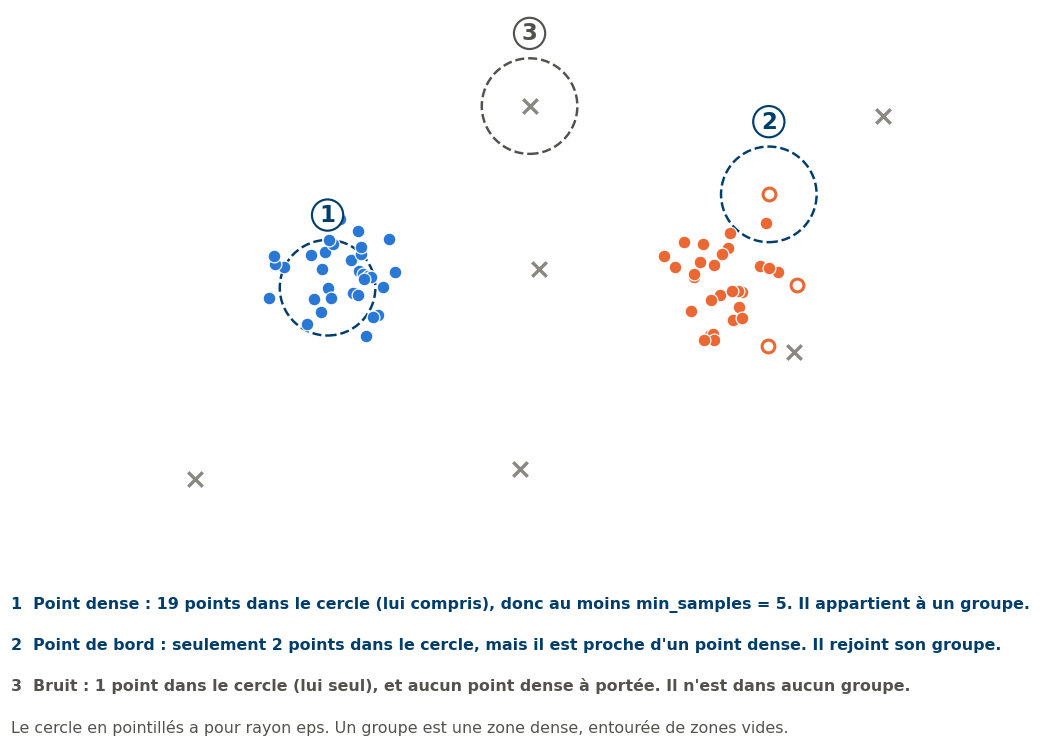

Avant de lancer DBSCAN sur les images, on réduit les 64 colonnes à 10 avec la **PCA**, vue au TD 3. Ces 10 colonnes gardent 74 % de la variation des images, et le calcul est plus rapide.

Références : M. Ester, H.-P. Kriegel, J. Sander, X. Xu, [*A Density-Based Algorithm for Discovering Clusters in Large Spatial Databases with Noise*](https://cdn.aaai.org/KDD/1996/KDD96-037.pdf), KDD-96, 1996 ; [`DBSCAN` (scikit-learn)](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html).

### Démo : DBSCAN sur les chiffres, avec eps = 0,7

In [ ]:
# Objectif : regrouper les chiffres avec DBSCAN, sans donner K.
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN

# PCA : on résume les 64 colonnes en 10 colonnes (vu au TD 3)
Z = PCA(n_components=10, random_state=42).fit_transform(X)
print("Tableau Z :", Z.shape)

# eps=0.7 : rayon du cercle ; min_samples=5 : nombre minimal d'images dans le cercle (elle comprise)
dbscan = DBSCAN(eps=0.7, min_samples=5)
groupes_db = dbscan.fit_predict(Z)           # le bruit reçoit le numéro -1

# On ne compte pas le numéro -1 comme un groupe
nb_groupes = len(set(groupes_db)) - (1 if -1 in groupes_db else 0)
part_bruit = (groupes_db == -1).mean()
print("Nombre de groupes :", nb_groupes)
print("Part d'images en bruit :", round(part_bruit, 3))

# Pureté : seulement sur les images rangées dans un groupe (hors bruit)
rangees = groupes_db != -1
tableau_db = pd.crosstab(groupes_db[rangees], y[rangees])
purete_db = tableau_db.max(axis=1).sum() / rangees.sum()
print("Pureté (hors bruit) :", round(purete_db, 3))

**Lecture du résultat.** Avec eps = 0,7, DBSCAN trouve **27 groupes** et met **30,4 %** des images dans le bruit. Sur les images rangées dans un groupe, la pureté est de **99,1 %**.

Ce nombre est élevé, mais il faut le lire avec prudence :
- il ne compte pas les 30,4 % d'images laissées de côté ;
- il y a 27 groupes pour 10 chiffres : DBSCAN coupe certains chiffres en plusieurs groupes. Par exemple, 6 groupes ont pour chiffre majoritaire le 8.

On ne peut donc pas comparer directement cette pureté à celle de K-means (79,4 %) : les deux méthodes ne traitent pas les mêmes images.

### Démo : voir les groupes et le bruit

Les nombres disent peu de choses. Regardons les images. Chaque ligne est l'un des 8 plus grands groupes. La dernière ligne montre 10 images du bruit.

In [ ]:
# Objectif : voir 10 images de chacun des 8 plus grands groupes de DBSCAN, puis 10 images du bruit.

# value_counts compte les images de chaque groupe (sans le bruit, numéro -1), du plus grand au plus petit
tailles = pd.Series(groupes_db[groupes_db != -1]).value_counts()
plus_grands = tailles.index[:8]

# Une ligne par groupe : son nom et les numéros de ses images ; la dernière ligne est le bruit
lignes = [(f"groupe {g}\n({tailles[g]} images)", np.where(groupes_db == g)[0]) for g in plus_grands]
lignes.append((f"bruit\n({(groupes_db == -1).sum()} images)", np.where(groupes_db == -1)[0]))

hasard = np.random.default_rng(0)      # graine fixée : on retrouve toujours les mêmes images
fig, axes = plt.subplots(len(lignes), 10, figsize=(8.6, 8.6))
for ligne, (nom, numeros) in enumerate(lignes):
    tirage = hasard.choice(numeros, 10, replace=False)      # 10 images tirées au hasard dans cette ligne
    for colonne, i in enumerate(tirage):
        axes[ligne, colonne].imshow(images[i], cmap="gray_r")
        axes[ligne, colonne].axis("off")
    axes[ligne, 0].text(-0.15, 0.5, nom, transform=axes[ligne, 0].transAxes, ha="right", va="center", fontsize=8)
plt.subplots_adjust(wspace=0.05, hspace=0.08, left=0.17)
plt.show()

**Lecture du résultat.** Les 8 plus grands groupes ne contiennent chacun presque qu'un seul chiffre, et ces chiffres sont tous différents : 0, 2, 3, 4, 5, 6, 7 et 9. La dernière ligne montre du bruit : 546 images, de tous les chiffres. DBSCAN garde les images qui ressemblent à beaucoup d'autres, et met de côté les autres.

### À vous : l'effet de eps

On relance DBSCAN avec trois valeurs de eps. Le reste ne change pas.

**À faire :** pour eps = 0,6, puis 0,8, puis 1,0, calculez le nombre de groupes et la part de bruit.

**Questions :**
1. Que deviennent le nombre de groupes et la part de bruit quand eps augmente ?
2. Que se passe-t-il quand eps est trop petit ? Et quand il est trop grand ?

In [ ]:
# Objectif : voir l'effet de eps sur le résultat de DBSCAN.

for eps in [0.6, 0.8, 1.0]:
    # TODO : lancer DBSCAN avec ce eps (et min_samples=5) sur Z, puis récupérer les groupes
    groupes_eps = ...
    # TODO : le nombre de groupes (sans compter le numéro -1) et la part d'images en bruit
    nb_groupes = ...
    part_bruit = ...
    print("eps =", eps, ":", nb_groupes, "groupes,", part_bruit, "d'images en bruit")

# Partie 4 : Regrouper pas à pas (clustering hiérarchique)

### Concept

Le **clustering hiérarchique** construit les groupes **pas à pas**, en partant du bas :
1. au départ, chaque image est **seule** dans son groupe : il y a 1 797 groupes ;
2. on **fusionne** les deux groupes les plus proches ;
3. on recommence jusqu'à n'avoir plus qu'un seul groupe.

On garde l'historique des fusions : c'est un arbre, le **dendrogramme**. Plus une fusion est haute dans l'arbre, plus les deux groupes fusionnés étaient éloignés. Pour obtenir K groupes, on **coupe l'arbre** à la bonne hauteur : chaque branche coupée est un groupe.

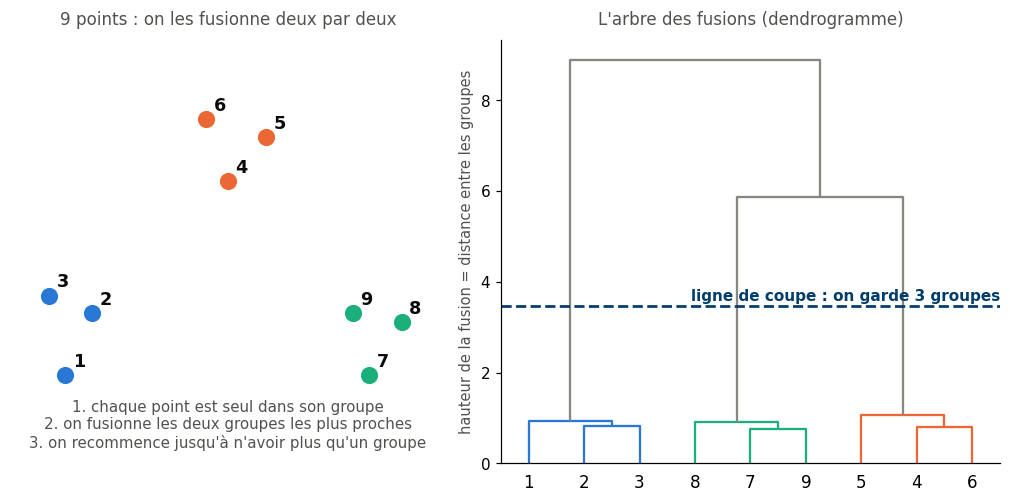

Il reste une question : comment mesurer la distance entre deux **groupes** ? C'est le **lien** (en anglais *linkage*). Deux choix possibles :
- le lien **ward** fusionne les deux groupes dont la fusion augmente le moins l'inertie (la mesure de la Partie 2) : les groupes restent compacts ;
- le lien **single** prend la distance entre les deux images les plus proches des deux groupes.

Références : [le clustering hiérarchique et ses liens](https://scikit-learn.org/stable/modules/clustering.html#hierarchical-clustering) (guide utilisateur de scikit-learn) ; [`dendrogram` (SciPy)](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.dendrogram.html).

### Démo : l'arbre de 50 images

In [ ]:
# Objectif : dessiner l'arbre des fusions sur un petit échantillon : 5 images de chaque chiffre.
from scipy.cluster.hierarchy import linkage, dendrogram

# 5 images au hasard pour chaque chiffre (50 images en tout) : avec 1 797 images, l'arbre serait illisible
hasard = np.random.default_rng(0)
numeros = np.concatenate([hasard.choice(np.where(y == c)[0], 5, replace=False) for c in range(10)])

# linkage calcule toutes les fusions avec le lien "ward" : chaque ligne est une fusion et sa hauteur
fusions = linkage(Z[numeros], method="ward")

# Ligne de coupe : entre la 10e et la 9e dernière fusion, pour garder 10 groupes
seuil = (fusions[-10, 2] + fusions[-9, 2]) / 2

plt.figure(figsize=(12, 4))
dendrogram(fusions, labels=y[numeros], color_threshold=seuil)    # chaque feuille porte le vrai chiffre de l'image
plt.axhline(seuil, color="black", linestyle="--")
plt.ylabel("Hauteur de la fusion")
plt.title("Dendrogramme de 50 images (sous chaque feuille : le vrai chiffre)")
plt.show()

**Lecture du résultat.** Chaque feuille est une image, et le nombre dessous est son vrai chiffre. La ligne pointillée coupe l'arbre en 10 groupes, de couleurs différentes. Sur ces 50 images, la pureté des 10 groupes est de **80 %** : beaucoup de branches ne contiennent qu'un seul chiffre, quelques-unes en mélangent deux.

### Démo : le clustering hiérarchique sur toutes les images

On garde 10 groupes et le lien ward, sur les 1 797 images (réduites à 10 colonnes par la PCA).

In [ ]:
# Objectif : regrouper les 1 797 images avec le clustering hiérarchique, en 10 groupes.
from sklearn.cluster import AgglomerativeClustering

# n_clusters=10 : on coupe l'arbre pour garder 10 groupes ; linkage="ward" : le lien de Ward
hierarchique = AgglomerativeClustering(n_clusters=10, linkage="ward")
groupes_h = hierarchique.fit_predict(Z)

# Tableau croisé et pureté, comme pour K-means
tableau_h = pd.crosstab(groupes_h, y, rownames=["groupe"], colnames=["vrai chiffre"])
purete_h = tableau_h.max(axis=1).sum() / len(y)
print("Pureté :", round(purete_h, 3))
print("Taille des groupes :", np.bincount(groupes_h))

**Lecture du résultat.** La pureté est de **78,9 %**, presque la même que K-means (79,4 %). Les groupes ont des tailles raisonnables : de 72 à 306 images.

Les deux méthodes donnent donc des regroupements de qualité semblable sur les chiffres. Le clustering hiérarchique a un avantage : l'arbre montre **comment** les groupes se fusionnent. Il n'est pas obligé de refaire le calcul pour changer K : il suffit de couper l'arbre plus haut ou plus bas.

### À vous : le choix du lien

**À faire :** refaites le clustering hiérarchique en 10 groupes avec le lien **single** au lieu de ward, puis calculez la pureté et la taille du plus gros groupe.

**Questions :**
1. Que valent la pureté et la taille du plus gros groupe avec le lien single ?
2. Pourquoi ce lien marche-t-il mal ici ?

In [ ]:
# Objectif : voir l'effet du lien sur le clustering hiérarchique.

# TODO : clustering hiérarchique en 10 groupes, mais avec linkage="single"
groupes_single = ...

# Tableau croisé, puis pureté et taille du plus gros groupe
tableau_single = pd.crosstab(groupes_single, y)
purete_single = ...                    # comme pour ward : maximum de chaque ligne, additionné, divisé par le nombre d'images
plus_gros_groupe = ...                 # np.bincount compte les images de chaque groupe ; max donne le plus grand
print("Pureté avec le lien single :", purete_single)
print("Taille du plus gros groupe :", plus_gros_groupe)

# Partie 5 : Grouper les sons, retrouve-t-on les personnes ?

### Concept

Au TD 4, on avait résumé chaque son par 4 descripteurs : la durée, le RMS, le ZCR et le centroïde. On avait aussi l'étiquette de chaque son : la personne qui parle (george, jackson ou lucas). Avec ces étiquettes, on savait reconnaître george et jackson dans 87,5 % des cas.

Ici, on cache les étiquettes. Le principe, en trois temps :
1. on donne à K-means les 60 sons, décrits par leurs 4 descripteurs, **sans dire qui parle** ;
2. K-means forme **3 groupes** : on choisit K = 3 parce qu'on sait qu'il y a 3 personnes ;
3. on **révèle** les étiquettes pour vérifier : chaque groupe est-il formé des sons d'une même personne ?

K-means ne connaît aucune personne. Ses groupes s'appellent 0, 1 et 2, et ces numéros ne veulent rien dire. C'est nous qui regardons ensuite si un groupe correspond à une personne, avec le tableau croisé et la pureté, comme pour les chiffres.

Il y a une précaution à prendre. Les descripteurs n'ont pas les mêmes unités : le centroïde est en hertz (de 654 à 1 918), le ZCR est entre 0,09 et 0,43. Or K-means regarde des distances. Sans précaution, le centroïde écrase tous les autres. On **standardise** chaque descripteur : on soustrait sa moyenne à chaque valeur, puis on divise le résultat par son écart-type. Ainsi, chaque descripteur a une moyenne de 0 et un écart-type de 1, ce qui permet de les comparer sur une même échelle.

**Exemple.** Un descripteur a 3 valeurs : 2, 4 et 6.
1. On calcule la moyenne : (2 + 4 + 6) ÷ 3 = 4.
2. On retire la moyenne à chaque valeur :

| Valeur initiale | Valeur − moyenne |
|---|---|
| 2 | 2 − 4 = −2 |
| 4 | 4 − 4 = 0 |
| 6 | 6 − 4 = 2 |

Les nouvelles valeurs sont donc −2, 0 et 2 : leur moyenne vaut 0.

3. On divise par l'écart-type, qui vaut environ 1,63 pour ces trois valeurs. Les valeurs deviennent −1,22, 0 et 1,22, et leur écart-type vaut 1.

### Démo : les descripteurs des 60 sons

In [ ]:
# Objectif : calculer les 4 descripteurs de chacun des 60 sons (comme au TD 4) et les ranger dans un tableau.
import wave, glob, os

DOSSIER_AUDIO = "../data/audio_fsdd_sample"
fichiers = sorted(glob.glob(f"{DOSSIER_AUDIO}/*.wav"))


def lire_son(chemin):
    # Lit un fichier .wav : renvoie les mesures (entre -1 et 1) et la fréquence d'échantillonnage
    with wave.open(chemin) as w:
        frequence = w.getframerate()
        mesures = np.frombuffer(w.readframes(w.getnframes()), dtype=np.int16)
    return mesures / 32768.0, frequence


def descripteurs(signal, frequence):
    duree = len(signal) / frequence                                   # durée en secondes
    rms = np.sqrt(np.mean(signal ** 2))                               # force moyenne du son
    zcr = np.mean(np.abs(np.diff(np.sign(signal))) > 0)               # taux de passage par zéro
    intensites = np.abs(np.fft.rfft(signal))                          # intensité de chaque fréquence
    frequences = np.fft.rfftfreq(len(signal), d=1 / frequence)        # valeur en Hz de chaque fréquence
    centroide = np.sum(frequences * intensites) / np.sum(intensites)  # fréquence moyenne du son
    return {"duree": duree, "rms": rms, "zcr": zcr, "centroide": centroide}


lignes = []
for chemin in fichiers:
    nom = os.path.basename(chemin)
    chiffre, locuteur, numero = nom[:-4].split("_")                   # "0_george_0.wav" -> "0", "george", "0"
    signal, frequence = lire_son(chemin)
    ligne = descripteurs(signal, frequence)
    ligne.update({"fichier": nom, "locuteur": locuteur})
    lignes.append(ligne)

DESCRIPTEURS = ["duree", "rms", "zcr", "centroide"]
sons = pd.DataFrame(lignes)[["fichier", "locuteur"] + DESCRIPTEURS]
print("Tableau des sons :", sons.shape)
print(sons[DESCRIPTEURS].describe().loc[["mean", "std", "min", "max"]].round(3))

**Lecture du résultat.** Le tableau a 60 lignes, une par son. Regardez l'écart-type (`std`) de chaque colonne : celui du centroïde vaut 302, celui du ZCR vaut 0,087. Le centroïde varie 3 485 fois plus que le ZCR, en valeur absolue. D'où la standardisation.

### Démo : 3 groupes, sans donner la personne

In [ ]:
# Objectif : regrouper les 60 sons en 3 groupes, sans donner le locuteur.
from sklearn.preprocessing import StandardScaler

# StandardScaler : pour chaque descripteur, on retire sa moyenne et on divise par son écart-type
sons_std = StandardScaler().fit_transform(sons[DESCRIPTEURS])
print("Moyenne de chaque descripteur après :", sons_std.mean(axis=0).round(2))
print("Écart-type de chaque descripteur après :", sons_std.std(axis=0).round(2))

# K = 3, parce qu'on sait qu'il y a 3 personnes ; on donne seulement les descripteurs, pas le locuteur
km_sons = KMeans(n_clusters=3, n_init=10, random_state=42)
groupes_sons = km_sons.fit_predict(sons_std)

# Tableau croisé : les groupes trouvés (lignes) et les vrais locuteurs (colonnes)
tableau_sons = pd.crosstab(groupes_sons, sons["locuteur"], rownames=["groupe"])
print(tableau_sons)

# Pureté : la part des sons qui ont le locuteur le plus fréquent de leur groupe
purete_sons = tableau_sons.max(axis=1).sum() / len(sons)
print("Pureté :", round(purete_sons, 3))

In [ ]:
# Objectif : savoir quelle pureté on obtiendrait en rangeant les sons au hasard dans des groupes de mêmes tailles.

hasard = np.random.default_rng(0)
puretes_hasard = []
for essai in range(1000):
    # permutation mélange les numéros de groupes : les tailles des groupes ne changent pas
    groupes_melanges = hasard.permutation(groupes_sons)
    tableau_hasard = pd.crosstab(groupes_melanges, sons["locuteur"])
    puretes_hasard.append(tableau_hasard.max(axis=1).sum() / len(sons))

print("Pureté moyenne au hasard :", round(np.mean(puretes_hasard), 3))
print("Pureté au hasard dans 95 % des essais, au plus :", round(np.quantile(puretes_hasard, 0.95), 3))

**Lecture du résultat.** Chaque groupe est dominé par une personne :
- groupe 0 : surtout **jackson** (17 sons sur 28)
- groupe 1 : surtout **george** (17 sons sur 23)
- groupe 2 : surtout **lucas** (7 sons sur 9)

La pureté est de **68,3 %**. Si on rangeait les sons au hasard dans des groupes de mêmes tailles, elle serait d'environ **42 %**, et elle dépasserait 48 % dans moins de 5 % des cas. K-means retrouve donc **en partie** les personnes, sans connaître leur nom. Mais pas parfaitement : les sons de lucas sont répartis dans les trois groupes (8 dans le groupe 0, 5 dans le groupe 1, 7 dans le groupe 2).

### À vous : et sans standardiser ?

**À faire :** refaites le regroupement en 3 groupes, mais directement sur les descripteurs, **sans standardiser**. Calculez la pureté.

**Questions :**
1. Que devient la pureté sans la standardisation ?
2. Pourquoi ?

In [ ]:
# Objectif : regrouper les sons sans standardiser les descripteurs.

# TODO : K-means avec 3 groupes (n_init=10, random_state=42), directement sur sons[DESCRIPTEURS]
groupes_bruts = ...

# Tableau croisé, puis pureté (même calcul que dans la démo)
tableau_bruts = pd.crosstab(groupes_bruts, sons["locuteur"])
purete_brute = ...
print("Pureté sans standardiser :", purete_brute)

> **À retenir :**
> - Le clustering regroupe des données **sans connaître la bonne réponse**. Les vrais chiffres servent seulement à vérifier (tableau croisé, pureté).
> - **K-means** demande de choisir K à l'avance. L'inertie et la silhouette aident à le choisir, mais elles ne décident pas seules.
> - **DBSCAN** n'a pas besoin de K, mais il faut bien régler eps. Il laisse de côté les images isolées : le bruit.
> - Le **clustering hiérarchique** construit un arbre des fusions. Le choix du lien (ward ou single) change fortement le résultat.
> - Avec K-means, il faut **standardiser** les colonnes qui n'ont pas les mêmes unités.

Vous avez maintenant vu, sur des images et sur des sons, comment regrouper des données sans connaître la bonne réponse : K-means, DBSCAN et le clustering hiérarchique.